# Part A: Variational autoencoders on CIFAR-10

# Submission Details

**Group:** Group 9  
**Course:** Unsupervised Deep Learning  
**Course Code:** S1-26_AIMLZG533

| Name | BITS ID |
|---|---|
| Meraj Hassan | 2025AE05085 |
| Himanshu Jha | 2025AG05420 |
| Sushil Kumar Behura | 2025AG05373 |
| Gundu Abhishek | 2025AG05701 |
| Nayudu Ganasai NagaSurya | 2025AG05591 |


Run all cells on the BITS Prayogshala GPU before submission. The full run is the default. Set `UDL_QUICK=1` only for a smoke test. Install the packages in `requirements.txt` before you start Jupyter.

In [ ]:
import time, json, random, os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR10
from torchvision.utils import make_grid, save_image

QUICK = os.environ.get("UDL_QUICK", "0") == "1"  # Default: full assignment run.
SEED = 0
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

OUT = Path("results_quick" if QUICK else "results")
(OUT / "models").mkdir(parents=True, exist_ok=True)
(OUT / "figs").mkdir(parents=True, exist_ok=True)

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

seed_all()
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "Apple MPS" if device == "mps" else "no gpu")

In [2]:
# CIFAR-10 kept as uint8 tensors on the GPU; we divide by 255 per batch -> pixels in [0, 1]
def load_cifar():
    tr = CIFAR10("data", train=True, download=True)
    te = CIFAR10("data", train=False, download=True)
    to_t = lambda ds: torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous()
    return to_t(tr), to_t(te)

train_u8, test_u8 = load_cifar()
if QUICK:
    train_u8, test_u8 = train_u8[:2000], test_u8[:500]
train_u8, test_u8 = train_u8.to(device), test_u8.to(device)
print(train_u8.shape, test_u8.shape)

def to01(x_u8):
    return x_u8.float() / 255.0

def batches(data, bs, shuffle=True):
    if shuffle:
        idx = torch.randperm(len(data), device=data.device)
        for i in range(0, len(data) - bs + 1, bs):
            yield to01(data[idx[i:i + bs]])
    else:
        for i in range(0, len(data), bs):
            yield to01(data[i:i + bs])

100%|██████████| 170M/170M [03:46<00:00, 753kB/s]  
c:\Users\ganas\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


torch.Size([50000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


In [5]:
def psnr(a, b):
    # a, b in [0,1]; PSNR per image, then averaged
    mse = ((a - b) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return (10 * torch.log10(1.0 / mse)).mean().item()

# FID: standard 2048-d InceptionV3 features, real statistics = the 10k CIFAR-10 test images
from torchmetrics.image.fid import FrechetInceptionDistance

class FIDScorer:
    def __init__(self, real_u8):
        self.fid_device = "cpu" if device == "mps" else device
        self.m = FrechetInceptionDistance(feature=2048, reset_real_features=False, normalize=True).to(self.fid_device)
        for i in range(0, len(real_u8), 500):
            self.m.update(to01(real_u8[i:i + 500]).to(self.fid_device), real=True)

    def __call__(self, fake):
        # fake: float tensor in [0,1], shape (N,3,32,32)
        self.m.reset()                       # real stats are kept
        for i in range(0, len(fake), 500):
            self.m.update(fake[i:i + 500].to(self.fid_device).clamp(0, 1), real=False)
        return float(self.m.compute())

fid_score = FIDScorer(test_u8)
N_FID = 500 if QUICK else 10000     # number of generated images used for FID

def show(imgs, nrow=8, title=None, size=7):
    g = make_grid(imgs[:nrow * nrow].cpu(), nrow=nrow, padding=1)
    plt.figure(figsize=(size, size)); plt.imshow(g.permute(1, 2, 0).numpy()); plt.axis("off")
    if title: plt.title(title)
    plt.show()

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to C:\Users\ganas/.cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:29<00:00, 3.22MB/s]


# Part A

## A.1  β-VAE

Conv encoder / decoder with BatchNorm, 128-d latent. Loss = BCE reconstruction (summed over pixels) + β · KL, both averaged over the batch.
For PSNR we decode the posterior mean, so the number doesn't depend on sampling noise.

In [6]:
class VAE(nn.Module):
    def __init__(self, zdim=128):
        super().__init__()
        down = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.ReLU())
        up = lambda i, o: nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.ReLU())
        self.enc = nn.Sequential(down(3, 64), down(64, 128), down(128, 256), nn.Flatten())   # 32 -> 4
        self.mu = nn.Linear(256 * 16, zdim)
        self.logvar = nn.Linear(256 * 16, zdim)
        self.fc = nn.Linear(zdim, 256 * 16)
        self.dec = nn.Sequential(up(256, 128), up(128, 64), nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Sigmoid())
        self.zdim = zdim

    def encode(self, x):
        h = self.enc(x)
        return self.mu(h), self.logvar(h)

    def decode(self, z):
        return self.dec(self.fc(z).view(-1, 256, 4, 4))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.decode(z), mu, logvar


def vae_loss(recon, x, mu, logvar, beta):
    bs = x.size(0)
    rec = F.binary_cross_entropy(recon, x, reduction="sum") / bs
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / bs
    return rec + beta * kl, rec, kl


@torch.no_grad()
def vae_test_psnr(model):
    model.eval()
    vals, n = 0.0, 0
    for x in batches(test_u8, 500, shuffle=False):
        mu, _ = model.encode(x)
        vals += psnr(model.decode(mu), x) * len(x); n += len(x)
    return vals / n


@torch.no_grad()
def vae_samples(model, n):
    model.eval()
    out = [model.decode(torch.randn(min(500, n - i), model.zdim, device=device)).cpu() for i in range(0, n, 500)]
    return torch.cat(out)


@torch.no_grad()
def vae_recons(model, data_u8):
    model.eval()
    out = []
    for x in batches(data_u8, 500, shuffle=False):
        out.append(model.decode(model.encode(x)[0]).cpu())
    return torch.cat(out)

In [7]:
BETAS = [1, 2, 4, 10]
VAE_EPOCHS = 3 if QUICK else 40
vae_res, vae_models = {}, {}

for beta in BETAS:
    seed_all()
    model = VAE().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    curve, t_epoch = [], []
    for ep in range(1, VAE_EPOCHS + 1):
        model.train(); t0 = time.time()
        tot = rec_t = kl_t = n = 0
        for x in batches(train_u8, 128):
            recon, mu, logvar = model(x)
            loss, rec, kl = vae_loss(recon, x, mu, logvar, beta)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tot += loss.item() * len(x); rec_t += rec.item() * len(x); kl_t += kl.item() * len(x); n += len(x)
        t_epoch.append(time.time() - t0)
        p = vae_test_psnr(model)
        curve.append(p)
        if ep % 5 == 0 or ep == 1 or ep == VAE_EPOCHS:
            print(f"beta={beta:<2} ep {ep:3d}  loss {tot/n:7.2f}  rec {rec_t/n:7.2f}  kl {kl_t/n:6.2f}  test PSNR {p:.2f}")

    t0 = time.time()
    samples = vae_samples(model, N_FID)
    t_sample = time.time() - t0
    fid_gen = fid_score(samples)
    fid_rec = fid_score(vae_recons(model, test_u8))
    vae_res[beta] = dict(psnr_curve=curve, final_psnr=curve[-1], fid_samples=fid_gen, fid_recon=fid_rec,
                         kl=kl_t / n, sec_per_epoch=float(np.mean(t_epoch)), sample_sec=t_sample)
    vae_models[beta] = model
    torch.save(model.state_dict(), OUT / "models" / f"vae_beta{beta}.pt")
    print(f"   -> beta={beta}: PSNR {curve[-1]:.2f} dB | FID(samples) {fid_gen:.1f} | FID(recon) {fid_rec:.1f}\n")

json.dump({str(k): v for k, v in vae_res.items()}, open(OUT / "partA_vae.json", "w"), indent=1)

beta=1  ep   1  loss 1887.26  rec 1850.33  kl  36.93  test PSNR 19.05
beta=1  ep   5  loss 1826.17  rec 1783.16  kl  43.01  test PSNR 20.21
beta=1  ep  10  loss 1821.22  rec 1777.04  kl  44.18  test PSNR 20.30
beta=1  ep  15  loss 1819.46  rec 1774.64  kl  44.82  test PSNR 20.53
beta=1  ep  20  loss 1818.06  rec 1772.92  kl  45.13  test PSNR 20.47
beta=1  ep  25  loss 1816.94  rec 1771.62  kl  45.32  test PSNR 20.57
beta=1  ep  30  loss 1816.43  rec 1770.97  kl  45.47  test PSNR 20.71
beta=1  ep  35  loss 1815.70  rec 1770.10  kl  45.59  test PSNR 20.58
beta=1  ep  40  loss 1815.18  rec 1769.46  kl  45.72  test PSNR 20.60
   -> beta=1: PSNR 20.60 dB | FID(samples) 146.0 | FID(recon) 145.1

beta=2  ep   1  loss 1924.00  rec 1878.52  kl  22.74  test PSNR 18.27
beta=2  ep   5  loss 1861.92  rec 1811.68  kl  25.12  test PSNR 19.06
beta=2  ep  10  loss 1856.61  rec 1804.78  kl  25.91  test PSNR 19.20
beta=2  ep  15  loss 1854.79  rec 1802.51  kl  26.14  test PSNR 19.31
beta=2  ep  20  loss 

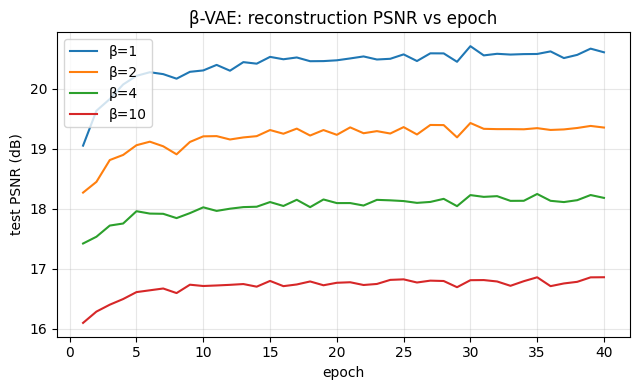

,β,PSNR (dB),FID samples,FID recon,KL/img,s/epoch
0,1,20.60,145.99,145.10,45.72,4.14
1,2,19.35,175.33,180.67,26.59,4.01
2,4,18.18,220.65,222.82,14.88,4.02
3,10,16.86,272.19,274.81,6.63,4.43


In [8]:
plt.figure(figsize=(6.5, 4))
for beta in BETAS:
    c = vae_res[beta]["psnr_curve"]
    plt.plot(range(1, len(c) + 1), c, label=f"β={beta}")
plt.xlabel("epoch"); plt.ylabel("test PSNR (dB)"); plt.title("β-VAE: reconstruction PSNR vs epoch")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(OUT / "figs" / "vae_psnr_vs_epoch.png", dpi=150); plt.show()

tab = pd.DataFrame([{"β": b, "PSNR (dB)": r["final_psnr"], "FID samples": r["fid_samples"], "FID recon": r["fid_recon"],
                     "KL/img": r["kl"], "s/epoch": r["sec_per_epoch"]} for b, r in vae_res.items()]).round(2)
tab

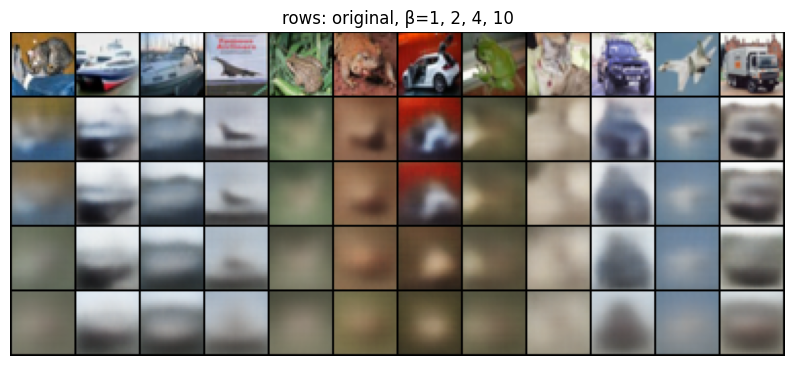

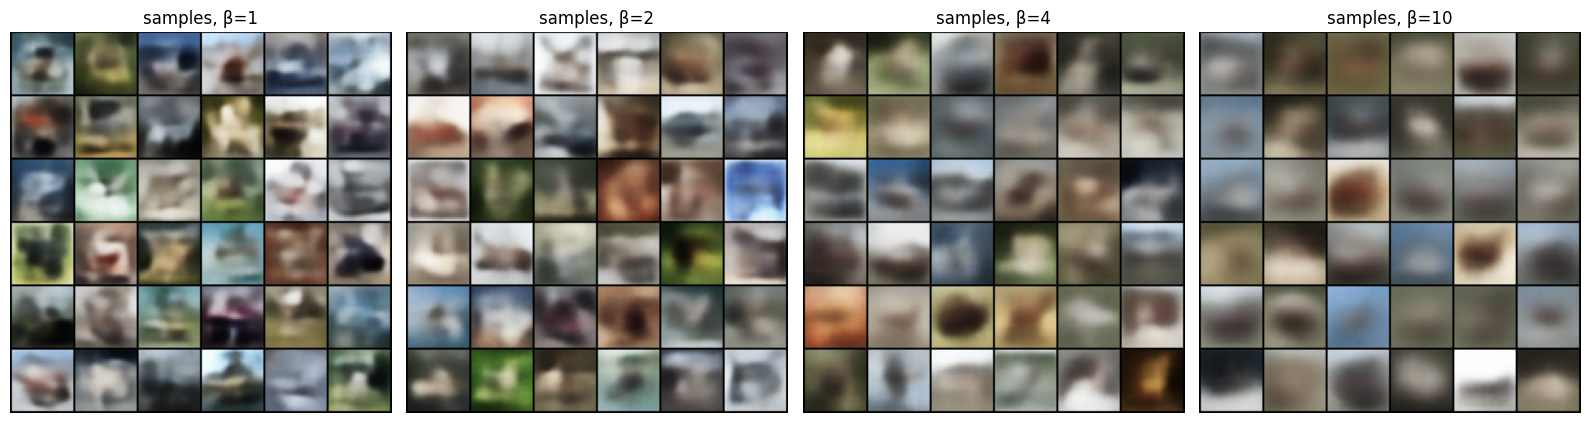

In [9]:
# reconstructions (top row = originals) and random samples for every β
x0 = to01(test_u8[:12])
rows = [x0.cpu()] + [vae_recons(vae_models[b], test_u8[:12]) for b in BETAS]
plt.figure(figsize=(10, 5))
plt.imshow(make_grid(torch.cat(rows), nrow=12, padding=1).permute(1, 2, 0).numpy()); plt.axis("off")
plt.title("rows: original, β=1, 2, 4, 10"); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(16, 4.4))
for a, b in zip(ax, BETAS):
    a.imshow(make_grid(vae_samples(vae_models[b], 36), nrow=6, padding=1).permute(1, 2, 0).numpy())
    a.axis("off"); a.set_title(f"samples, β={b}")
plt.tight_layout(); plt.show()

# 100 samples of the β=1 model for the Part C comparison
save_image(vae_samples(vae_models[1], 100), OUT / "figs" / "vae_beta1_100.png", nrow=10, padding=1)

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(OUT / 'figs' / 'vae_beta1_100.png')))

### β-VAE observations

The PSNR fell from 20.60 dB at β=1 to 16.86 dB at β=10. The KL term fell from 45.72 to 6.63 per image. Stronger regularization made reconstructions and random samples blurrier. Sample FID rose from 145.99 to 272.19, so β=1 gave the best sample score in this run. Reconstruction FID followed the same direction. These results use the saved full-run outputs above; recalculate them in the required lab run.


## A.2  VQ-VAE with a PixelCNN prior

Encoder downsamples 32x32 -> 16x16, so each image becomes a 16x16 grid of code indices (256 tokens). Two residual blocks in both encoder and decoder.
The codebook is updated with exponential moving averages (as in the VQ-VAE paper's appendix), plus a commitment loss of 0.25 on the encoder. Codes that stop being used get re-seeded from encoder outputs now and then, otherwise a big codebook collapses to a handful of entries.

Pipeline per K: train VQ-VAE -> encode the whole train/test set into index maps -> train PixelCNN on the train maps -> sample new maps -> decode with the VQ-VAE decoder.

In [10]:
class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.f = nn.Sequential(nn.ReLU(), nn.Conv2d(c, c, 3, 1, 1), nn.ReLU(), nn.Conv2d(c, c, 1))
    def forward(self, x):
        return x + self.f(x)


class Quantizer(nn.Module):
    def __init__(self, K, D, commit=0.25, decay=0.99, eps=1e-5):
        super().__init__()
        self.K, self.D, self.commit, self.decay, self.eps = K, D, commit, decay, eps
        self.register_buffer("codebook", torch.randn(K, D))
        self.register_buffer("cluster_size", torch.ones(K))
        self.register_buffer("embed_avg", self.codebook.clone())

    def _flat(self, z):
        return z.permute(0, 2, 3, 1).reshape(-1, self.D)

    @torch.no_grad()
    def init_from(self, z):
        flat = self._flat(z)
        pick = flat[torch.randperm(len(flat), device=flat.device)[:self.K]]
        self.codebook.copy_(pick); self.embed_avg.copy_(pick); self.cluster_size.fill_(1.0)

    @torch.no_grad()
    def revive(self, z, thresh=0.5):
        dead = self.cluster_size < thresh
        n = int(dead.sum())
        if n == 0:
            return 0
        flat = self._flat(z)
        pick = flat[torch.randint(len(flat), (n,), device=flat.device)]
        self.codebook[dead] = pick; self.embed_avg[dead] = pick; self.cluster_size[dead] = 1.0
        return n

    def forward(self, z):
        B, D, H, W = z.shape
        flat = self._flat(z)
        dist = flat.pow(2).sum(1, keepdim=True) - 2 * flat @ self.codebook.t() + self.codebook.pow(2).sum(1)
        idx = dist.argmin(1)
        if self.training:
            with torch.no_grad():
                onehot = F.one_hot(idx, self.K).type(flat.dtype)
                self.cluster_size.mul_(self.decay).add_(onehot.sum(0), alpha=1 - self.decay)
                self.embed_avg.mul_(self.decay).add_(onehot.t() @ flat, alpha=1 - self.decay)
                n = self.cluster_size.sum()
                cs = (self.cluster_size + self.eps) / (n + self.K * self.eps) * n
                self.codebook.copy_(self.embed_avg / cs.unsqueeze(1))
        q = self.codebook[idx].view(B, H, W, D).permute(0, 3, 1, 2)
        loss = self.commit * F.mse_loss(z, q.detach())
        q = z + (q - z).detach()                     # straight-through
        return q, loss, idx.view(B, H, W)


class VQVAE(nn.Module):
    def __init__(self, K, D=64, ch=128):
        super().__init__()
        self.K = K
        self.enc = nn.Sequential(
            nn.Conv2d(3, ch // 2, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(ch // 2, ch, 3, 1, 1), ResBlock(ch), ResBlock(ch),
            nn.ReLU(), nn.Conv2d(ch, D, 1))
        self.vq = Quantizer(K, D)
        self.dec = nn.Sequential(
            nn.Conv2d(D, ch, 3, 1, 1), ResBlock(ch), ResBlock(ch), nn.ReLU(),
            nn.ConvTranspose2d(ch, ch // 2, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(ch // 2, 3, 3, 1, 1), nn.Sigmoid())

    def forward(self, x):
        z = self.enc(x)
        q, vq_loss, idx = self.vq(z)
        return self.dec(q), vq_loss, idx, z

    def decode_idx(self, idx):
        q = self.vq.codebook[idx].permute(0, 3, 1, 2)
        return self.dec(q)


@torch.no_grad()
def vq_test_psnr(model):
    model.eval()
    tot, n = 0.0, 0
    for x in batches(test_u8, 500, shuffle=False):
        tot += psnr(model(x)[0], x) * len(x); n += len(x)
    return tot / n


@torch.no_grad()
def vq_recons(model, data_u8):
    model.eval()
    return torch.cat([model(x)[0].cpu() for x in batches(data_u8, 500, shuffle=False)])


@torch.no_grad()
def encode_tokens(model, data_u8):
    model.eval()
    return torch.cat([model(x)[2] for x in batches(data_u8, 500, shuffle=False)])

In [11]:
class MaskedConv(nn.Conv2d):
    """conv whose kernel only sees pixels above / to the left. 'A' also hides the centre pixel."""
    def __init__(self, kind, *args, **kw):
        super().__init__(*args, **kw)
        k = self.kernel_size[0]
        mask = torch.zeros_like(self.weight)
        mask[:, :, :k // 2, :] = 1
        mask[:, :, k // 2, :k // 2] = 1
        if kind == "B":
            mask[:, :, k // 2, k // 2] = 1
        self.register_buffer("mask", mask)

    def forward(self, x):
        return F.conv2d(x, self.weight * self.mask, self.bias, self.stride, self.padding)


class PixBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.f = nn.Sequential(nn.ReLU(), nn.Conv2d(c, c // 2, 1), nn.ReLU(),
                               MaskedConv("B", c // 2, c // 2, 3, padding=1),
                               nn.ReLU(), nn.Conv2d(c // 2, c, 1))
    def forward(self, x):
        return x + self.f(x)


class PixelCNN(nn.Module):
    def __init__(self, K, c=128, n_blocks=8):
        super().__init__()
        self.emb = nn.Embedding(K, c)
        self.first = MaskedConv("A", c, c, 7, padding=3)
        self.blocks = nn.Sequential(*[PixBlock(c) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.ReLU(), nn.Conv2d(c, c, 1), nn.ReLU(), nn.Conv2d(c, K, 1))

    def forward(self, tok):                      # tok: (B,H,W) long -> logits (B,K,H,W)
        h = self.emb(tok).permute(0, 3, 1, 2)
        return self.head(self.blocks(self.first(h)))


@torch.no_grad()
def sample_tokens(pcnn, n, H, W, bs=500):
    pcnn.eval()
    outs = []
    for i in range(0, n, bs):
        b = min(bs, n - i)
        t = torch.zeros(b, H, W, dtype=torch.long, device=device)
        for y in range(H):
            for x in range(W):
                p = F.softmax(pcnn(t)[:, :, y, x], dim=1)
                t[:, y, x] = torch.multinomial(p, 1).squeeze(1)
        outs.append(t)
    return torch.cat(outs)


@torch.no_grad()
def pcnn_nll(pcnn, tokens):
    # mean negative log-likelihood per token (nats)
    pcnn.eval(); tot, n = 0.0, 0
    for i in range(0, len(tokens), 500):
        t = tokens[i:i + 500]
        tot += F.cross_entropy(pcnn(t), t, reduction="sum").item(); n += t.numel()
    return tot / n


def codebook_stats(tokens, K):
    counts = torch.bincount(tokens.flatten(), minlength=K).float().cpu()
    p = counts / counts.sum()
    ent = -(p[p > 0] * p[p > 0].log()).sum()
    return dict(used=int((counts > 0).sum()), usage=float((counts > 0).float().mean()),
                perplexity=float(ent.exp()), counts=counts.tolist())

In [12]:
KS = [512, 256, 128]
VQ_EPOCHS = 3 if QUICK else 30
PCNN_EPOCHS = 2 if QUICK else 20
vq_res, vq_models, pcnns = {}, {}, {}

for K in KS:
    print(f"================ K = {K} ================")
    seed_all()
    model = VQVAE(K).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=5e-4)

    # data-dependent codebook init from the first batch
    with torch.no_grad():
        model.vq.init_from(model.enc(to01(train_u8[:512])))

    curve, t_epoch, step = [], [], 0
    for ep in range(1, VQ_EPOCHS + 1):
        model.train(); t0 = time.time(); mse_t = n = 0
        for x in batches(train_u8, 128):
            recon, vq_loss, idx, z = model(x)
            mse = F.mse_loss(recon, x)
            loss = mse + vq_loss
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            step += 1
            if step % 100 == 0 and ep <= VQ_EPOCHS * 0.8:
                model.vq.revive(z.detach())
            mse_t += mse.item() * len(x); n += len(x)
        t_epoch.append(time.time() - t0)
        curve.append(vq_test_psnr(model))
        if ep % 5 == 0 or ep == 1 or ep == VQ_EPOCHS:
            print(f"K={K} ep {ep:3d}  train mse {mse_t/n:.5f}  test PSNR {curve[-1]:.2f}")

    # discrete latent maps
    tok_train = encode_tokens(model, train_u8)
    tok_test = encode_tokens(model, test_u8)
    cb = codebook_stats(tok_test, K)
    print(f"latent map shape {tuple(tok_train.shape[1:])}, codes used {cb['used']}/{K}, perplexity {cb['perplexity']:.1f}")

    # PixelCNN prior on the train latents
    pcnn = PixelCNN(K).to(device)
    popt = torch.optim.Adam(pcnn.parameters(), lr=1e-3)
    n_steps = PCNN_EPOCHS * (len(tok_train) // 128)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(popt, n_steps)
    pc_curve = []
    t_pc = time.time()
    for ep in range(1, PCNN_EPOCHS + 1):
        pcnn.train()
        perm = torch.randperm(len(tok_train), device=device)
        for i in range(0, len(perm) - 127, 128):
            t = tok_train[perm[i:i + 128]]
            loss = F.cross_entropy(pcnn(t), t)
            popt.zero_grad(set_to_none=True); loss.backward(); popt.step(); sched.step()
        pc_curve.append((loss.item(), pcnn_nll(pcnn, tok_test)))
        print(f"   PixelCNN ep {ep:2d}  train {pc_curve[-1][0]:.3f}  test NLL {pc_curve[-1][1]:.3f}")
    t_pc = time.time() - t_pc

    # sample new latents -> decode -> FID
    t0 = time.time()
    new_tok = sample_tokens(pcnn, N_FID, *tok_train.shape[1:])
    with torch.no_grad():
        gen = torch.cat([model.decode_idx(new_tok[i:i + 500]).cpu() for i in range(0, N_FID, 500)])
    t_sample = time.time() - t0
    fid_gen = fid_score(gen)
    fid_rec = fid_score(vq_recons(model, test_u8))
    print(f"   -> K={K}: PSNR {curve[-1]:.2f} | FID(samples) {fid_gen:.1f} | FID(recon) {fid_rec:.1f}\n")

    vq_res[K] = dict(psnr_curve=curve, final_psnr=curve[-1], fid_samples=fid_gen, fid_recon=fid_rec,
                     codebook=cb, pcnn_curve=pc_curve, sec_per_epoch=float(np.mean(t_epoch)),
                     pcnn_train_sec=t_pc, sample_sec=t_sample)
    vq_models[K], pcnns[K] = model, pcnn
    torch.save(model.state_dict(), OUT / "models" / f"vqvae_k{K}.pt")
    torch.save(pcnn.state_dict(), OUT / "models" / f"pixelcnn_k{K}.pt")
    save_image(gen[:100], OUT / "figs" / f"vqvae_k{K}_100.png", nrow=10, padding=1)

json.dump({str(k): v for k, v in vq_res.items()}, open(OUT / "partA_vqvae.json", "w"), indent=1)

================ K = 512 ================
K=512 ep   1  train mse 0.00911  test PSNR 25.37
K=512 ep   5  train mse 0.00121  test PSNR 30.16
K=512 ep  10  train mse 0.00087  test PSNR 31.33
K=512 ep  15  train mse 0.00080  test PSNR 31.81
K=512 ep  20  train mse 0.00074  test PSNR 31.55
K=512 ep  25  train mse 0.00071  test PSNR 31.31
K=512 ep  30  train mse 0.00069  test PSNR 31.76
latent map shape (16, 16), codes used 512/512, perplexity 427.6
   PixelCNN ep  1  train 4.848  test NLL 4.758
   PixelCNN ep  2  train 4.599  test NLL 4.639
   PixelCNN ep  3  train 4.501  test NLL 4.562
   PixelCNN ep  4  train 4.407  test NLL 4.524
   PixelCNN ep  5  train 4.644  test NLL 4.495
   PixelCNN ep  6  train 4.447  test NLL 4.478
   PixelCNN ep  7  train 4.452  test NLL 4.464
   PixelCNN ep  8  train 4.388  test NLL 4.455
   PixelCNN ep  9  train 4.357  test NLL 4.445
   PixelCNN ep 10  train 4.368  test NLL 4.439
   PixelCNN ep 11  train 4.423  test NLL 4.434
   PixelCNN ep 12  train 4.376  te

  K  PSNR (dB)  FID samples  FID recon  codes used  usage  perplexity  PixelCNN test NLL  s/epoch  sampling s
512     31.757       81.807     10.086         512    1.0     427.579              4.417   22.594     424.209
256     31.373       79.730     11.194         256    1.0     216.832              3.898   18.127     410.720
128     30.542       79.853     14.532         128    1.0     111.282              3.350   22.556     478.437


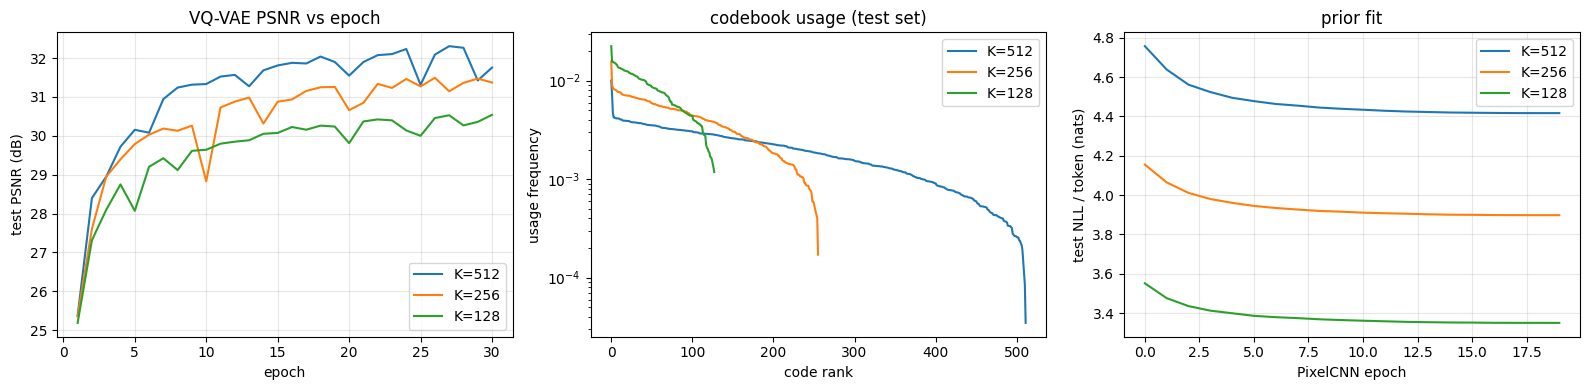

In [13]:
tab = pd.DataFrame([{"K": k, "PSNR (dB)": r["final_psnr"], "FID samples": r["fid_samples"], "FID recon": r["fid_recon"],
                     "codes used": r["codebook"]["used"], "usage": r["codebook"]["usage"],
                     "perplexity": r["codebook"]["perplexity"], "PixelCNN test NLL": r["pcnn_curve"][-1][1],
                     "s/epoch": r["sec_per_epoch"], "sampling s": r["sample_sec"]} for k, r in vq_res.items()]).round(3)
print(tab.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for K in KS:
    c = vq_res[K]["psnr_curve"]; ax[0].plot(range(1, len(c) + 1), c, label=f"K={K}")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("test PSNR (dB)"); ax[0].set_title("VQ-VAE PSNR vs epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
for K in KS:
    cnt = np.sort(np.array(vq_res[K]["codebook"]["counts"]))[::-1]
    ax[1].plot(cnt / cnt.sum(), label=f"K={K}")
ax[1].set_yscale("log"); ax[1].set_xlabel("code rank"); ax[1].set_ylabel("usage frequency"); ax[1].set_title("codebook usage (test set)"); ax[1].legend()
for K in KS:
    ax[2].plot([t for _, t in vq_res[K]["pcnn_curve"]], label=f"K={K}")
ax[2].set_xlabel("PixelCNN epoch"); ax[2].set_ylabel("test NLL / token (nats)"); ax[2].set_title("prior fit"); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "figs" / "vqvae_summary.png", dpi=150); plt.show()

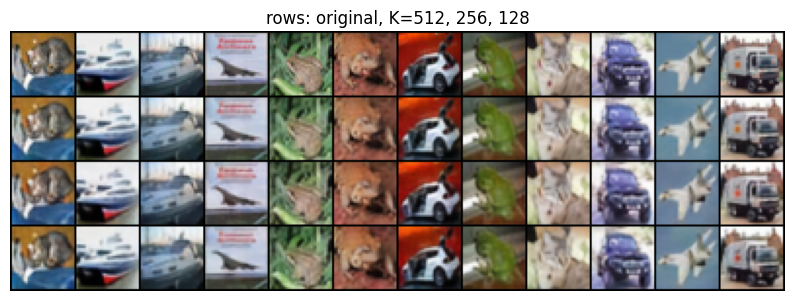

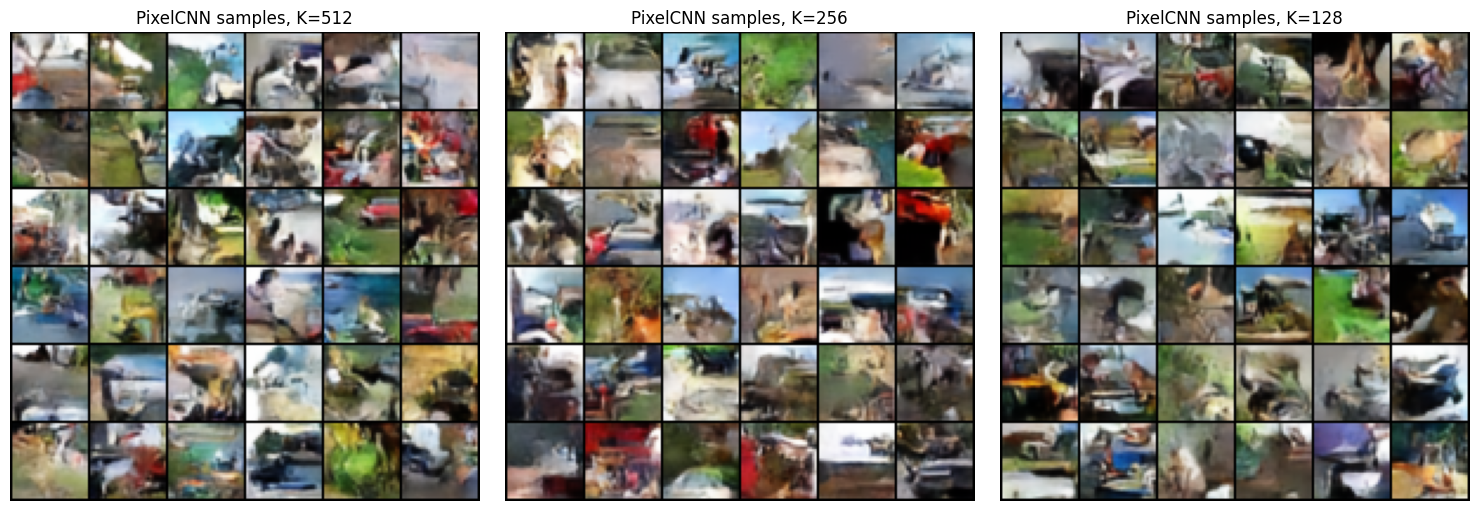

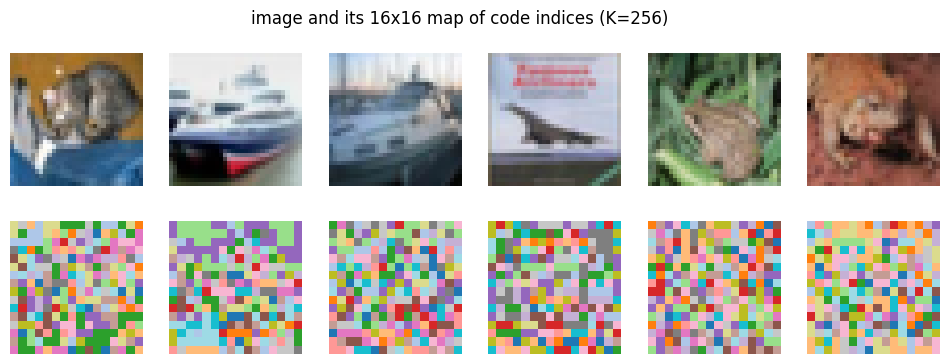

In [14]:
x0 = to01(test_u8[:12]).cpu()
rows = [x0] + [vq_recons(vq_models[K], test_u8[:12]) for K in KS]
plt.figure(figsize=(10, 4.5))
plt.imshow(make_grid(torch.cat(rows), nrow=12, padding=1).permute(1, 2, 0).numpy()); plt.axis("off")
plt.title("rows: original, K=512, 256, 128"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, K in zip(ax, KS):
    seed_all()
    tk = sample_tokens(pcnns[K], 36, 16, 16)
    with torch.no_grad():
        im = vq_models[K].decode_idx(tk).cpu()
    a.imshow(make_grid(im, nrow=6, padding=1).permute(1, 2, 0).numpy()); a.axis("off"); a.set_title(f"PixelCNN samples, K={K}")
plt.tight_layout(); plt.show()

# what the discrete latents look like for a few test images
tk = encode_tokens(vq_models[256], test_u8[:6]).cpu()
fig, ax = plt.subplots(2, 6, figsize=(12, 4))
for i in range(6):
    ax[0, i].imshow(to01(test_u8[i]).permute(1, 2, 0).cpu().numpy()); ax[0, i].axis("off")
    ax[1, i].imshow(tk[i].numpy(), cmap="tab20"); ax[1, i].axis("off")
fig.suptitle("image and its 16x16 map of code indices (K=256)"); plt.show()

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(OUT / 'figs' / 'vqvae_k256_100.png')))

### VQ-VAE observations

All codes were used for each tested K. At K=512, test PSNR was 31.76 dB and codebook perplexity was 427.58. At K=256, PSNR was 31.37 dB and sample FID was 79.73. At K=128, PSNR fell to 30.54 dB, while sample FID stayed near 79.85. Reconstruction FID rose as K became smaller. The decoded reconstructions preserve more detail than β-VAE outputs, but PixelCNN samples have less exact structure than reconstructions. These results use the saved full-run outputs above; recalculate them in the required lab run.
